## MNIST handwritten digits prediction

The MNIST (Modified National Institute of Standards and Technology) digits dataset is a widely used dataset in the field of machine learning and computer vision. It is commonly used for training and testing image processing systems, particularly in the context of handwritten digit recognition.

<img src="https://miro.medium.com/max/800/1*LyRlX__08q40UJohhJG9Ow.png" align="left" width="600">

### Import Python libraries

In [1]:
# Libraries
import os
import logging
import platform
import warnings
from datetime import datetime
from platform import python_version

import numpy as np
import matplotlib.pyplot as plt

# Set TensorFlow log level to suppress warnings (must be set before
# TensorFlow is imported)
logging.disable(logging.WARNING)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# TensorFlow and Keras (imported after setting the log level)
# pylint: disable=wrong-import-position
from tensorflow import keras
from tensorflow.keras import layers

# pylint: enable=wrong-import-position

# Ignore warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

I0000 00:00:1792953587.177638   11105 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792953588.282036   11105 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792953623.975777   11105 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792953623.981317   11105 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/workspaces/python_machine_learning_basics/08_Neural_Networks


### Prepare the data

In [2]:
# Model / data parameters
num_classes = 10
input_shape = (28, 28, 1)

# The data, split between train and test sets
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Scale images to the [0, 1] range
X_train = X_train.astype("float32") / 255
X_test = X_test.astype("float32") / 255

# Make sure images have shape (28, 28, 1)
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)
print("X_train shape:", X_train.shape)
print(X_train.shape[0], "train samples")
print(X_test.shape[0], "test samples")

# Convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
X_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


### Show single handwritten digits

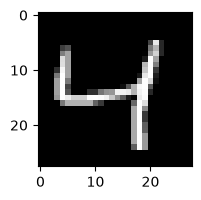

In [3]:
# Show single digit image
image = X_train[2]  # Change index in [] to show other digits
# Figure showing the digit as a grey-scale image
plt.figure(figsize=(2, 2))
plt.imshow(image, cmap='gray')
plt.show()

In [4]:
# Show shape of single digit image
print(X_train[2].shape)

(28, 28, 1)


### Initialize the model 

In [5]:
# Linear stack of layers
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ]
)
# model.summary()

### Train the model

In [6]:
# Define batch size and epochs
batch_size = 128
epochs = 5

# Compile the model
model.compile(
    loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"]
)

# Train the model
model.fit(
    X_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.8901 - loss: 0.3668 - val_accuracy: 0.9803 - val_loss: 0.0775
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.9676 - loss: 0.1051 - val_accuracy: 0.9863 - val_loss: 0.0536
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.9752 - loss: 0.0807 - val_accuracy: 0.9888 - val_loss: 0.0442
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.9797 - loss: 0.0661 - val_accuracy: 0.9893 - val_loss: 0.0390
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.9816 - loss: 0.0594 - val_accuracy: 0.9903 - val_loss: 0.0386


### Evaluate the trained model

In [7]:
# Calculate the test loss and accuracy
score = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(score[0], 4))
print("Test accuracy:", round(score[1], 4))

Test loss: 0.0342
Test accuracy: 0.9887


### Jupyter notebook --footer info-- (please always provide this at the end of each submitted notebook)

In [8]:
# Show operating system, date/time and Python version
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-25 18:42:19
Python Version: 3.11.17
-----------------------------------
